In [29]:
import os
import sys
from pathlib import Path

# Add the project root (one level up from the notebooks folder) to the Python path
project_root = str(Path(os.getcwd()).parent)
if project_root not in sys.path:
    sys.path.append(project_root)

print(f"Added {project_root} to Python path.")


Added /Users/fionaxie/OMSC/DL2026/mnist-math to Python path.


In [30]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [35]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
#from sklearn.manifold import TSNE

from data_pipeline import get_arithmetic_dataloader
from models.jepa_model import IJepaModel
from utils.experiment_config import load_experiment_config, apply_cli_overrides
from utils.common import get_device, set_seed
from evaluation.metrics import rollout_evaluation


In [74]:
def load_model_from_run(run_dir: Path):
    config = load_experiment_config(Path(run_dir) / "config.json")
    #config = apply_cli_overrides(config, {})
    set_seed(config.run.seed)
    device = get_device()
    
    if config.model.op_embedding_type == "embedding":
        model_ops = sorted(list(set(config.data.ops) | set(test_ops)))
    else:
        model_ops = config.data.ops

    encoder_kwargs: dict[str, Any] = {
        'normalize': config.model.encoder_normalize,
        'activation': config.model.activation
    }
    if config.model.encoder_type.lower() in ['mlp', 'cnn']:
        encoder_kwargs['hidden_dim'] = config.model.encoder_hidden_dim

    elif config.model.encoder_type.lower() == 'vit':
        encoder_kwargs.update({
            "patch_size": config.model.patch_size,
            "d_model": config.model.d_model,
            "depth": config.model.depth,
            "nhead": config.model.nhead,
            "mlp_dim": config.model.mlp_dim,
            "use_cls_token": config.model.use_cls_token
        })
    classifier_kwargs = {'num_classes': config.model.num_classes,
                         'hidden_dim': config.model.classifier_hidden_dim}
    kwargs_model: dict[str, Any] = {'encoder_kwargs': encoder_kwargs, 'classifier_kwargs': classifier_kwargs}

    kwargs_vicreg: dict[str, Any] = {'cls_loss_weight': config.optim.cls_weight,
                                    'use_vic_reg': config.model.use_vic_reg,
                                    'lamda': config.model.lamda,
                                    'gamma': config.model.gamma,
                                    'miu': config.model.miu,
                                    'nu': config.model.nu}

    kwargs_comp: dict[str, Any] = {'use_composition_loss': getattr(config.model, 'use_composition_loss', False),
                                   'composition_lambda': getattr(config.model, 'composition_lambda', 0.0),
                                   'training_ops': config.data.ops,
                                   'composition_ops': getattr(config.model, 'composition_ops', []),
                                   'composition_detach_teacher': getattr(config.model, 'composition_detach_teacher', True)}

    model = IJepaModel(
        ops=model_ops,
        latent_dim=config.model.latent_dim,
        op_embed_dim=config.model.op_embed_dim,
        op_embedding_type=config.model.op_embedding_type,
        encoder_type=config.model.encoder_type,
        predictor_hidden_dim=tuple(config.model.predictor_hidden_dim),
        predictor_dropout=config.model.predictor_dropout,
        predictor_normalize=config.model.predictor_normalize,
        predictor_type=config.model.predictor_type,
        residual_scale_init=config.model.residual_scale_init,
        rotation_angle_init=config.model.rotation_angle_init,
        rotation_learnable=config.model.rotation_learnable,
        rotation_init_mode=config.model.rotation_init_mode,
        rotation_period=config.model.rotation_period,
        joint_cls_training=config.optim.cls_weight > 0,
        momentum =config.model.momentum,
        **kwargs_model
    ).to(device)

    ckpt = torch.load(run_dir / "checkpoint_final.pt", map_location=device, weights_only=True)
    model.load_state_dict(ckpt["model"])
    model.eval()
    print(f'Model is saved at epoch = {ckpt["epoch"]} ')

    return model, config
    #model, config = load_model_from_run(JEPA_PRIMITIVE_DIR)

In [76]:
run_dir = (
    Path(project_root) / "runs/jepa/20260429-131035-primitive_ops1_mlp"
)
model_op1, config_op1 = load_model_from_run(run_dir)

Model is saved at epoch = 10 


In [33]:
def load_data(config, test_ops = None):
     # Use test_ops if specified, otherwise default to training ops
    if test_ops is None:
        test_ops = config.data.test_ops if config.data.test_ops else config.data.ops

    train_loader = get_arithmetic_dataloader(
        dataset_name=config.data.dataset,
        batch_size=config.data.batch_size,
        ops=config.data.ops,
        is_train=True,
        data_root=config.data.data_root,
        num_workers=config.data.num_workers,
    )
    seen_test_loader = None
    if test_ops != config.data.ops:
        seen_test_loader = get_arithmetic_dataloader(
            dataset_name=config.data.dataset,
            batch_size=config.data.batch_size,
            ops=config.data.ops,
            is_train=False,
            data_root=config.data.data_root,
            num_workers=config.data.num_workers,
        )

    test_loader = get_arithmetic_dataloader(
        dataset_name=config.data.dataset,
        batch_size=config.data.batch_size,
        ops=test_ops,
        is_train=False,
        data_root=config.data.data_root,
        num_workers=config.data.num_workers,
    )

    if config.run.overfit > 0:
        # this section is not needed.
        snap = FixedSampleDataset(train_loader.dataset, config.run.overfit)
        bs = min(config.data.batch_size, config.run.overfit)
        train_loader = DataLoader(
            snap,
            batch_size=bs,
            shuffle=True,
            num_workers=config.data.num_workers,
        )
        test_loader = DataLoader(
            snap,
            batch_size=bs,
            shuffle=False,
            num_workers=config.data.num_workers,
        )
        seen_test_loader = test_loader
        print(f"[overfit] snapshotted {config.run.overfit} samples (train == eval set)")
    return {
        'train_loader':train_loader,
        'test_loader':test_loader,
        'seen_test_loader':seen_test_loader
    }
    

In [34]:
def compute_rollout_accuracies(premitive_ops, scales, run_dir, device):
    knn_accuracies = []
    cls_accuracies = []
    cls_losses = []
    #model, config = load_model_from_run(run_dir)
    
    for scale in scales:
        test_ops = list(premitive_ops * scale)
        print (scale, test_ops)
        model, config = load_model_from_run(run_dir)
        dataloader = load_data(config, test_ops = test_ops)
        rollout_accuracy = rollout_evaluation(model, dataloader['test_loader'], 
                                              device, config.data.ops, test_ops, config.model.num_classes)
        knn_accuracies.append([scale, rollout_accuracy['knn_accuracy']])
        cls_accuracies.append([scale, rollout_accuracy['cls_accuracy']])
        cls_losses.append([scale, rollout_accuracy['cls_loss']])
    return {
        'knn_accuracies': np.array(knn_accuracies),
        'cls_accuracies': np.array(cls_accuracies),
        'cls_losses': np.array(cls_losses)
    }

## 1. Test the robustness of roll-out compositional operations on different primitive operations 
#### Make sure checkpoint.pt is the model at the end of training instead of the one with best_accuracy if model evaluation fails and best_accuracy is useless.  

In [67]:
def plot_rollout_accuracy(accuracies: dict[str, np.ndarray], primitive_ops = None):
    knn_accuracies = accuracies['knn_accuracies']
    cls_accuracies = accuracies['cls_accuracies']
    cls_losses = accuracies['cls_losses']
    fig, ax1 = plt.subplots()
    ax1.plot(knn_accuracies[:, 0], knn_accuracies[:,1], '.-', color='r', label='knn_accuracy')
    ax1.plot(cls_accuracies[:, 0], cls_accuracies[:,1], '.-', color = 'k',label='cls_accuracy')
    ax1.legend(loc='lower left')
    ax1.set_ylim([0.9, 1])
    ax2 = ax1.twinx()
    ax2.plot(cls_losses[:, 0], cls_losses[:,1], '.-', color = 'b', label='test_loss')
    ax2.legend(loc= 'upper right')
    ax2.set_ylim([0, 0.2])
    
    ax1.set_xlabel('Scale')
    ax1.set_ylabel('Accuracies')
    ax2.set_ylabel('Loss')
    

### 1.1 primitive operations = [+1, -1] 

In [48]:
jepa_primitive_op_1_dir= (
    Path(project_root) / "runs/jepa/20260428-154450-primitive_ops1_mlp"
)
scales = np.arange(1, 10)
premitive_ops = np.array([+1, -1])
device = get_device()
run_dir = jepa_primitive_op_1_dir
primitive_op1_results = compute_rollout_accuracies(premitive_ops, scales, run_dir, device)

1 [np.int64(1), np.int64(-1)]
2 [np.int64(2), np.int64(-2)]
3 [np.int64(3), np.int64(-3)]
4 [np.int64(4), np.int64(-4)]
5 [np.int64(5), np.int64(-5)]
6 [np.int64(6), np.int64(-6)]
7 [np.int64(7), np.int64(-7)]
8 [np.int64(8), np.int64(-8)]
9 [np.int64(9), np.int64(-9)]


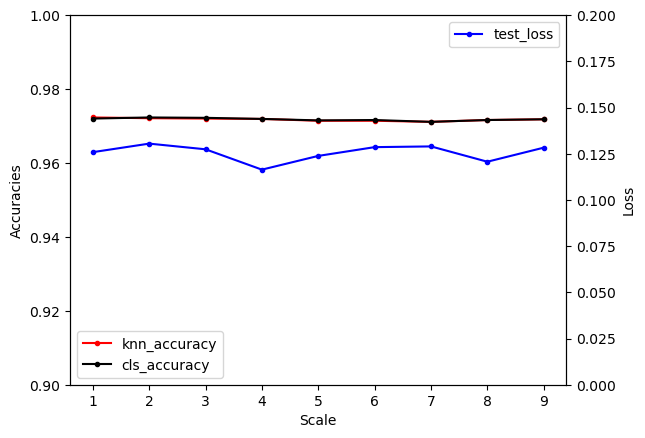

In [68]:
plot_rollout_accuracy(primitive_op1_results)


### 1.2 primitive operations = [+2, -2] 

In [66]:
jepa_primitive_op_2_dir = (
    Path(project_root) / "runs/jepa/20260428-144606-primitive_ops2_mlp"
)
print(run_dir)
scales = np.arange(1, 10)
premitive_ops = np.array([+2, -2])
device = get_device()
run_dir = jepa_primitive_op_2_dir
primitive_op2_results = compute_rollout_accuracies(premitive_ops, scales, run_dir, device)

/Users/fionaxie/OMSC/DL2026/mnist-math/runs/jepa/20260428-144606-primitive_ops2_mlp
1 [np.int64(2), np.int64(-2)]
2 [np.int64(4), np.int64(-4)]
3 [np.int64(6), np.int64(-6)]
4 [np.int64(8), np.int64(-8)]
5 [np.int64(10), np.int64(-10)]
6 [np.int64(12), np.int64(-12)]
7 [np.int64(14), np.int64(-14)]
8 [np.int64(16), np.int64(-16)]
9 [np.int64(18), np.int64(-18)]


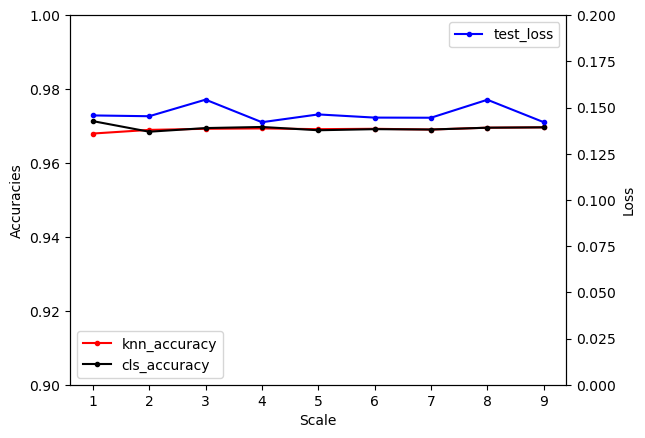

In [69]:
plot_rollout_accuracy(primitive_op2_results)

### 1.3 Compare the latent space in primitive op1 and primitive op2

In [70]:
from evaluation.metrics import collect_latent_diagnostics

In [ ]:
model_op1, config_op1 = load_model_from_run(jepa_primitive_op_2_dir)
premitive_ops = np.array([+1, -1])
test_ops = premitive_ops 
dataloader = load_data(config_op1, test_ops = test_ops)
latents_op1 = collect_latent_diagnostics(
        model_op1,
        dataloader,
        device: torch.device,
        config_op1.model.num_classes,


In [ ]:
model_op1, config_op1 = load_model_from_run(jepa_primitive_op_2_dir)

### 1.4 Compare the action embedding in primitive op1 and oprimitive op2

In [77]:
freqs = torch.arange(32, dtype=torch.float32) % 5 
freqs = freqs + 1.0
print(freqs)
init_angles = 2.0 * freqs / 10
print(init_angles)

tensor([1., 2., 3., 4., 5., 1., 2., 3., 4., 5., 1., 2., 3., 4., 5., 1., 2., 3.,
        4., 5., 1., 2., 3., 4., 5., 1., 2., 3., 4., 5., 1., 2.])
tensor([0.2000, 0.4000, 0.6000, 0.8000, 1.0000, 0.2000, 0.4000, 0.6000, 0.8000,
        1.0000, 0.2000, 0.4000, 0.6000, 0.8000, 1.0000, 0.2000, 0.4000, 0.6000,
        0.8000, 1.0000, 0.2000, 0.4000, 0.6000, 0.8000, 1.0000, 0.2000, 0.4000,
        0.6000, 0.8000, 1.0000, 0.2000, 0.4000])


In [80]:
init_angles.unsqueeze(0), init_angles.unsqueeze(0).shape

(tensor([[0.2000, 0.4000, 0.6000, 0.8000, 1.0000, 0.2000, 0.4000, 0.6000, 0.8000,
          1.0000, 0.2000, 0.4000, 0.6000, 0.8000, 1.0000, 0.2000, 0.4000, 0.6000,
          0.8000, 1.0000, 0.2000, 0.4000, 0.6000, 0.8000, 1.0000, 0.2000, 0.4000,
          0.6000, 0.8000, 1.0000, 0.2000, 0.4000]]),
 torch.Size([1, 32]))

In [81]:
action_values = torch.ones(
                5,
                dtype=init_angles.dtype,
                device=init_angles.device,
            )
action_values, 

tensor([1., 1., 1., 1., 1.])

In [83]:
action_values.view(-1).float().unsqueeze(-1), action_values.view(-1).float().unsqueeze(-1).shape

(tensor([[1.],
         [1.],
         [1.],
         [1.],
         [1.]]),
 torch.Size([5, 1]))

In [84]:
action_values = action_values.view(-1).float().unsqueeze(-1)

In [86]:
c = action_values * init_angles.unsqueeze(0)
c, c.shapex 

(tensor([[0.2000, 0.4000, 0.6000, 0.8000, 1.0000, 0.2000, 0.4000, 0.6000, 0.8000,
          1.0000, 0.2000, 0.4000, 0.6000, 0.8000, 1.0000, 0.2000, 0.4000, 0.6000,
          0.8000, 1.0000, 0.2000, 0.4000, 0.6000, 0.8000, 1.0000, 0.2000, 0.4000,
          0.6000, 0.8000, 1.0000, 0.2000, 0.4000],
         [0.2000, 0.4000, 0.6000, 0.8000, 1.0000, 0.2000, 0.4000, 0.6000, 0.8000,
          1.0000, 0.2000, 0.4000, 0.6000, 0.8000, 1.0000, 0.2000, 0.4000, 0.6000,
          0.8000, 1.0000, 0.2000, 0.4000, 0.6000, 0.8000, 1.0000, 0.2000, 0.4000,
          0.6000, 0.8000, 1.0000, 0.2000, 0.4000],
         [0.2000, 0.4000, 0.6000, 0.8000, 1.0000, 0.2000, 0.4000, 0.6000, 0.8000,
          1.0000, 0.2000, 0.4000, 0.6000, 0.8000, 1.0000, 0.2000, 0.4000, 0.6000,
          0.8000, 1.0000, 0.2000, 0.4000, 0.6000, 0.8000, 1.0000, 0.2000, 0.4000,
          0.6000, 0.8000, 1.0000, 0.2000, 0.4000],
         [0.2000, 0.4000, 0.6000, 0.8000, 1.0000, 0.2000, 0.4000, 0.6000, 0.8000,
          1.0000, 0.2000, 0

In [88]:
import torch.nn as nn
nn.Parameter(init_angles)

Parameter containing:
tensor([0.2000, 0.4000, 0.6000, 0.8000, 1.0000, 0.2000, 0.4000, 0.6000, 0.8000,
        1.0000, 0.2000, 0.4000, 0.6000, 0.8000, 1.0000, 0.2000, 0.4000, 0.6000,
        0.8000, 1.0000, 0.2000, 0.4000, 0.6000, 0.8000, 1.0000, 0.2000, 0.4000,
        0.6000, 0.8000, 1.0000, 0.2000, 0.4000], requires_grad=True)

### Learning curve for rotation_angle when rotation_learnable=True

In [121]:
from typing import Any
import math

In [202]:
def load_history(run_dir: Path):
    with open(run_dir / "history.json") as f:
        return json.load(f)
def get_metrics(history: dict[str, Any]) -> dict[str,Any]:
    
    epochs = [ep["epoch"] for ep in history] 
    acc_train = [ep["train"]["accuracy"] for ep in history]
    acc_test = [ep["test"]["accuracy"] for ep in history]
    jepa_loss_train = [ep["train"]["jepa_loss"] for ep in history]
    jepa_loss_test = [ep["test"]["jepa_loss"] for ep in history]
    rotation_angles = np.array([ep["train"]["rotation_angles"] for ep in history])
    
    return {
        "epochs": epochs,
        "acc_train": acc_train,
        "acc_test": acc_test,
        "jepa_loss_train": jepa_loss_train,
        "jepa_loss_test": jepa_loss_test,
        "rotation_angles": rotation_angles
    }

def plot_learning_curves(metrics, ylim_loss=None, savefile=None):
    if not isinstance(metrics, list):
        raise ValueError(f"metrics need to be a list of metric dictionary")
    nrows = 1
    figsize = (5, 2)
    if len(metrics)==2:
        nrows = 2
        figsize = (5, 4)
    fig, axes = plt.subplots(nrows, 2, figsize=figsize)

    for r in range(axes.shape[0]):
        axes[r, 0].plot(metrics[r]['epochs'], metrics[r]['acc_train'], color="blue", linewidth=2, label="Train")
        axes[r, 0].plot(metrics[r]['epochs'], metrics[r]['acc_test'], color="red", linewidth=2, label="Test")
        axes[r, 1].plot(metrics[r]['epochs'], metrics[r]['jepa_loss_train'], color="blue", linewidth=2, label="Train")
        axes[r, 1].plot(metrics[r]['epochs'], metrics[r]['jepa_loss_test'], color="red", linewidth=2, label="Test")
        
    ylabels = ["Accuracy", "loss"]
    locs = ["lower right", "upper right"]
    for i, ax in enumerate(axes[-1,:]):
        ax.set_xlabel("Epoch")
        ax.legend(loc = locs[i])
    for i, ax in enumerate(axes.flat):
        if i % 2 == 0: 
            ax.set_ylim([0,1])
            ax.set_ylabel(ylabels[0])
        if i % 2 == 1:
            ax.set_ylabel(ylabels[1])
            if ylim_loss is None:
                ylim = [41, 43.5]
                yticks = [41, 42, 43]
                yticklabels = [str(tick) for tick in yticks]
                ax.set_ylim(ylim)
                ax.set_yticks(yticks)
                ax.set_yticklabels(yticklabels)
    plt.tight_layout(h_pad=0.1, w_pad=0.15)
    if savefile is None:
        plt.savefig('./learning_curve_block_rotation.png')
    else:
        plt.savefig('./learning_curve_block_rotation'+ savefile + '.png')
        
    plt.show()
    
def plot_angles_learning_curve(metrics, yticks=None, savefile=None):
    if not isinstance(metrics, list):
        raise ValueError(f"metrics need to be a list of metric dictionary")
    
    pi = math.pi
    fig, axes = plt.subplots(1, 2, figsize=(5, 2))
    if yticks is None:
            yticks = [-pi/5, 0, pi/5, pi/2.5]
            ytickslabels = [r'$-\pi/5$', r'$0$', r'$\pi/5$', r'$2\pi/5$']
    elif len(yticks) == 0:
       #     yticks = [-2*pi, -pi, 0, pi, 2*pi]
       #     ytickslabels = [r'$-2\pi$', r'$-\pi$',r'$0$', r'$\pi$', r'$2\pi$']
    #elif len(yticks) > 0:
            yticks = [-pi, 0, pi, 2*pi]
            ytickslabels = [ r'$-\pi$',r'$0$', r'$\pi$', r'$2\pi$']
            
    for i, ax in enumerate(axes.flat):
        ax.plot(metrics[i]["epochs"], metrics[i]["rotation_angles"])
        ax.set_xlabel("Epoch")
        ax.set_yticks(yticks)
        ax.set_yticklabels(ytickslabels)
    axes[0].set_ylabel("Rotation angles")
    plt.tight_layout(pad=0.1)
    if savefile is None:
        plt.savefig('./learning_curve_angles.png')
    else: 
        plt.savefig('./learning_curve_angles' + savefile + '.png')
    plt.show()
    
    

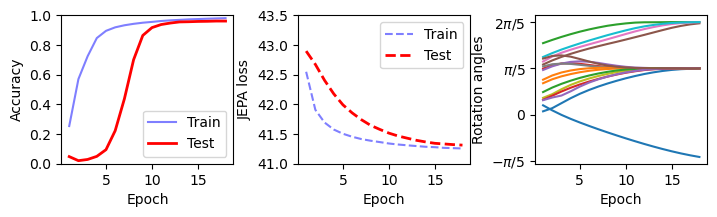

In [146]:
MF_ROT_RUN_DIR = (
    Path(project_root) / "runs/jepa/20260502-115803-multi-freq_mlp")
mf_history = load_history(MF_ROT_RUN_DIR)
plot_learning_curves(mf_history)


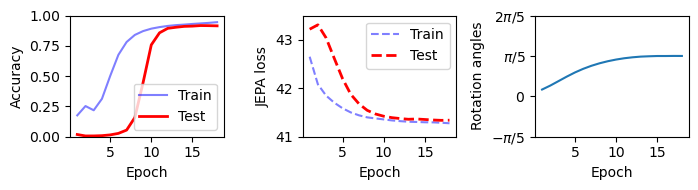

In [142]:
MF_ROT_RUN_DIR = (
    Path(project_root) / "runs/jepa/20260502-130711-single-freq_mlp")
sf_history = load_history(MF_ROT_RUN_DIR)
plot_learning_curves(sf_history)

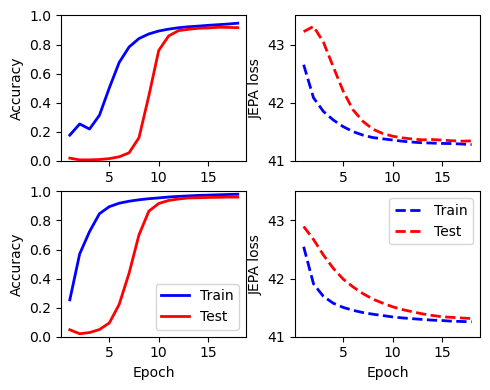

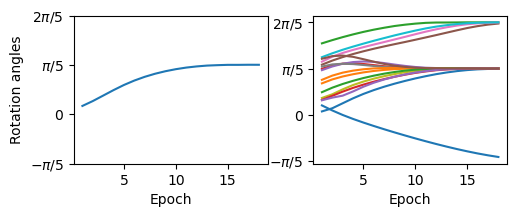

In [167]:
# latent_dim = 32
MF_ROT_RUN_DIR = (
    Path(project_root) / "runs/jepa/20260502-115803-multi-freq_mlp")
mf_history = load_history(MF_ROT_RUN_DIR)
mf_metrics = get_metrics(mf_history)

SF_ROT_RUN_DIR = (
    Path(project_root) / "runs/jepa/20260502-130711-single-freq_mlp")
sf_history = load_history(SF_ROT_RUN_DIR)
sf_metrics = get_metrics(sf_history)

metrics = [sf_metrics, mf_metrics]
plot_learning_curves(metrics)
plot_angles_learning_curve(metrics)


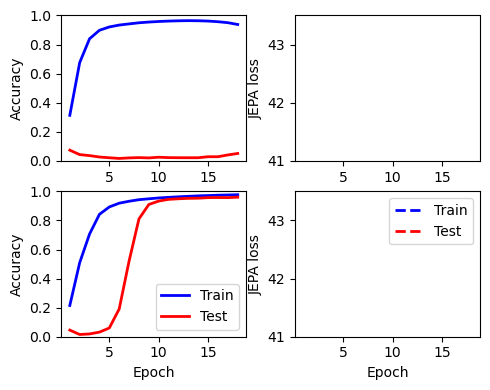

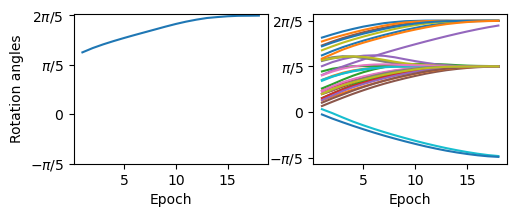

In [168]:
# latent_dim = 64
MF_ROT_RUN_DIR = (
    Path(project_root) / "runs/jepa/20260502-181056-multi-freq-ld64_mlp")
mf_history = load_history(MF_ROT_RUN_DIR)
mf_metrics = get_metrics(mf_history)

SF_ROT_RUN_DIR = (
    Path(project_root) / "runs/jepa/20260502-180037-single-freq-ld64_mlp")
sf_history = load_history(SF_ROT_RUN_DIR)
sf_metrics = get_metrics(sf_history)

metrics = [sf_metrics, mf_metrics]
plot_learning_curves(metrics)
plot_angles_learning_curve(metrics)


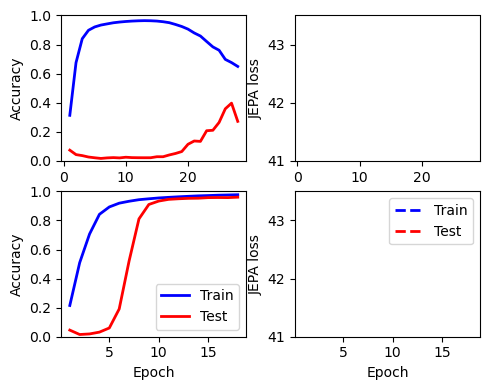

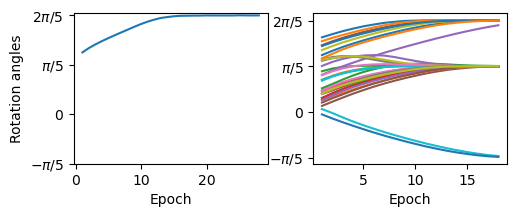

In [172]:
# latent_dim = 64
MF_ROT_RUN_DIR = (
    Path(project_root) / "runs/jepa/20260502-181056-multi-freq-ld64_mlp")
mf_history = load_history(MF_ROT_RUN_DIR)
mf_metrics = get_metrics(mf_history)

SF_ROT_RUN_DIR = (
    Path(project_root) / "runs/jepa/20260502-182833-single-freq-ld64_mlp")
sf_history = load_history(SF_ROT_RUN_DIR)
sf_metrics = get_metrics(sf_history)

metrics = [sf_metrics, mf_metrics]
plot_learning_curves(metrics)
plot_angles_learning_curve(metrics)

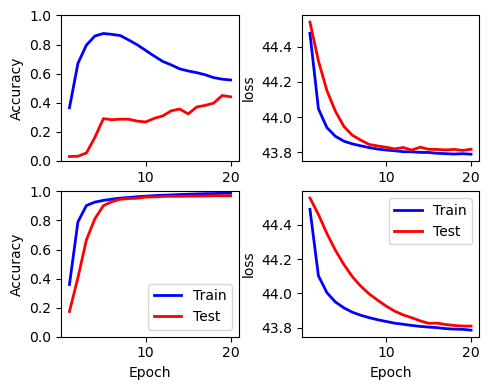

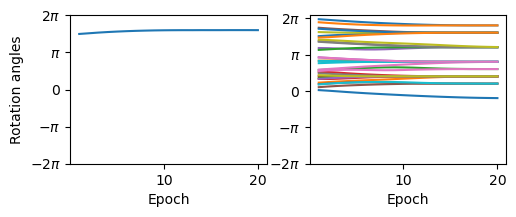

In [204]:
# latent 64, full initial angles over 2pi
MF_ROT_RUN_DIR = (
    Path(project_root) / "runs/jepa/20260502-190515-multi-freq-ld64-2pi_init_mlp") 
mf_history = load_history(MF_ROT_RUN_DIR)
mf_metrics = get_metrics(mf_history)

SF_ROT_RUN_DIR = (
    Path(project_root) / "runs/jepa/20260502-191850-single-freq-ld64-2pi_init_mlp")
sf_history = load_history(SF_ROT_RUN_DIR)
sf_metrics = get_metrics(sf_history)

metrics = [sf_metrics, mf_metrics]
plot_learning_curves(metrics, ylim_loss=[])
plot_angles_learning_curve(metrics, yticks =[])

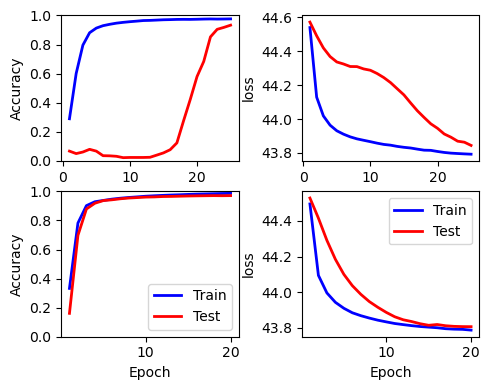

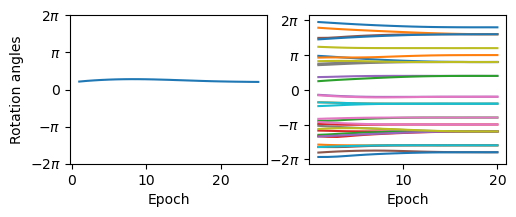

In [203]:
# latent 64, full initial angles over -2pi-2pi
MF_ROT_RUN_DIR = (
    Path(project_root) / "runs/jepa/20260502-200414-multi-freq-ld64-2pi_-2pi_init_mlp") 
mf_history = load_history(MF_ROT_RUN_DIR)
mf_metrics = get_metrics(mf_history)

SF_ROT_RUN_DIR = (
    Path(project_root) / "runs/jepa/20260502-214052-single-freq-ld64-2pi_-2pi_init_mlp")#20260502-203501-single-freq-ld64-2pi_-2pi_init_mlp")
sf_history = load_history(SF_ROT_RUN_DIR)
sf_metrics = get_metrics(sf_history)

metrics = [sf_metrics, mf_metrics]
plot_learning_curves(metrics, ylim_loss =[], savefile="_-2pi-2pi_init")
plot_angles_learning_curve(metrics, yticks =[], savefile="_-2pi-2pi_init")

In [182]:
mfr_similarity_matrix = [[ 1.0000,  0.7527,  0.1743, -0.3846, -0.7328, -0.8352, -0.7268, -0.3392,
          0.2263,  0.7540],
        [ 0.7527,  1.0000,  0.7559,  0.2028, -0.3559, -0.7110, -0.8429, -0.7318,
         -0.3698,  0.1723],
        [ 0.1743,  0.7559,  1.0000,  0.7703,  0.2271, -0.3220, -0.6893, -0.8439,
         -0.7460, -0.4133],
        [-0.3846,  0.2028,  0.7703,  1.0000,  0.7684,  0.2365, -0.3060, -0.7038,
         -0.8376, -0.7518],
        [-0.7328, -0.3559,  0.2271,  0.7684,  1.0000,  0.7802,  0.2615, -0.3269,
         -0.7026, -0.8403],
        [-0.8352, -0.7110, -0.3220,  0.2365,  0.7802,  1.0000,  0.7832,  0.2259,
         -0.3364, -0.6969],
        [-0.7268, -0.8429, -0.6893, -0.3060,  0.2615,  0.7832,  1.0000,  0.7598,
          0.2111, -0.3307],
        [-0.3392, -0.7318, -0.8439, -0.7038, -0.3269,  0.2259,  0.7598,  1.0000,
          0.7735,  0.2603],
        [ 0.2263, -0.3698, -0.7460, -0.8376, -0.7026, -0.3364,  0.2111,  0.7735,
          1.0000,  0.7913],
        [ 0.7540,  0.1723, -0.4133, -0.7518, -0.8403, -0.6969, -0.3307,  0.2603,
          0.7913,  1.0000]]

In [184]:
mfr_similarity_matrix = np.array(mfr_similarity_matrix) # -2pi--2pi init

<Axes: >

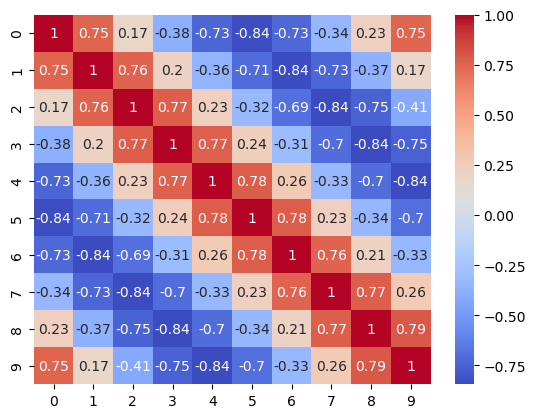

In [186]:
sns.heatmap(mfr_similarity_matrix, cmap='coolwarm',annot=True) 

In [192]:
sfr = [[ 1.0000,  0.7871,  0.2395, -0.3521, -0.8081, -0.9632, -0.7852, -0.3180,
          0.2946,  0.7866],
        [ 0.7871,  1.0000,  0.7815,  0.2743, -0.3280, -0.7935, -0.9664, -0.8052,
         -0.3358,  0.2467],
        [ 0.2395,  0.7815,  1.0000,  0.8087,  0.3054, -0.3006, -0.7655, -0.9665,
         -0.8179, -0.3868],
        [-0.3521,  0.2743,  0.8087,  1.0000,  0.8003,  0.2912, -0.2919, -0.7677,
         -0.9655, -0.8230],
        [-0.8081, -0.3280,  0.3054,  0.8003,  1.0000,  0.8017,  0.3153, -0.2836,
         -0.7731, -0.9666],
        [-0.9632, -0.7935, -0.3006,  0.2912,  0.8017,  1.0000,  0.8144,  0.3222,
         -0.2891, -0.7567],
        [-0.7852, -0.9664, -0.7655, -0.2919,  0.3153,  0.8144,  1.0000,  0.8069,
          0.2973, -0.2854],
        [-0.3180, -0.8052, -0.9665, -0.7677, -0.2836,  0.3222,  0.8069,  1.0000,
          0.7992,  0.3148],
        [ 0.2946, -0.3358, -0.8179, -0.9655, -0.7731, -0.2891,  0.2973,  0.7992,
          1.0000,  0.8180],
        [ 0.7866,  0.2467, -0.3868, -0.8230, -0.9666, -0.7567, -0.2854,  0.3148,
          0.8180,  1.0000]]

In [193]:
sfr_similarity_matrix = np.array(sfr)

<Axes: >

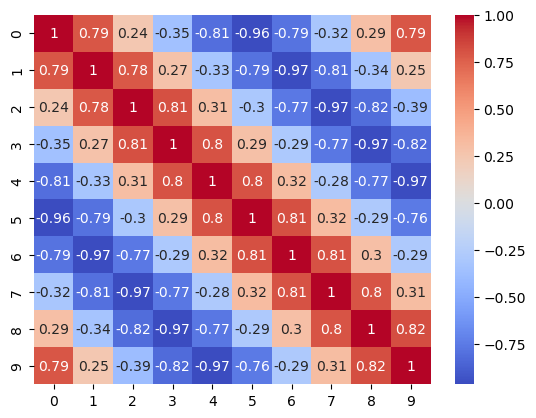

In [194]:
sns.heatmap(sfr_similarity_matrix, cmap='coolwarm',annot=True)

In [198]:
mf_2pi_init = [[ 1.0000, -0.0181, -0.2214, -0.2453, -0.2716,  0.5046, -0.2809, -0.2062,
         -0.2039, -0.0236],
        [-0.0181,  1.0000, -0.0204, -0.2380, -0.2521, -0.2767,  0.4883, -0.2955,
         -0.2348, -0.2244],
        [-0.2214, -0.0204,  1.0000, -0.0077, -0.2238, -0.2369, -0.2877,  0.5129,
         -0.2898, -0.2446],
        [-0.2453, -0.2380, -0.0077,  1.0000, -0.0212, -0.2094, -0.2529, -0.2751,
          0.5077, -0.2913],
        [-0.2716, -0.2521, -0.2238, -0.0212,  1.0000,  0.0030, -0.2014, -0.2258,
         -0.2953,  0.5164],
        [ 0.5046, -0.2767, -0.2369, -0.2094,  0.0030,  1.0000, -0.0014, -0.2030,
         -0.2052, -0.2673],
        [-0.2809,  0.4883, -0.2877, -0.2529, -0.2014, -0.0014,  1.0000, -0.0345,
         -0.2215, -0.2112],
        [-0.2062, -0.2955,  0.5129, -0.2751, -0.2258, -0.2030, -0.0345,  1.0000,
         -0.0443, -0.2173],
        [-0.2039, -0.2348, -0.2898,  0.5077, -0.2953, -0.2052, -0.2215, -0.0443,
          1.0000, -0.0442],
        [-0.0236, -0.2244, -0.2446, -0.2913,  0.5164, -0.2673, -0.2112, -0.2173,
         -0.0442,  1.0000]]

<Axes: >

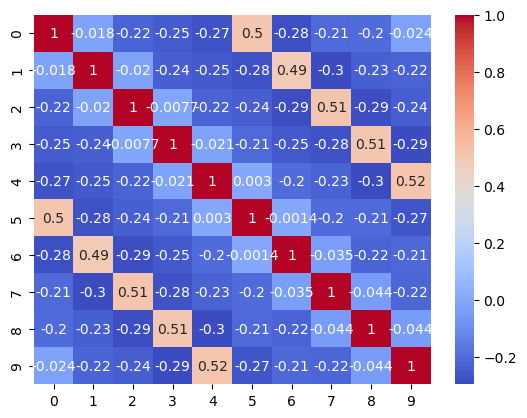

In [200]:
mf_similarity_matrix1 = np.array(mf_2pi_init)
sns.heatmap(mf_similarity_matrix1, cmap='coolwarm',annot=True)